In [11]:
import numpy as np
from matplotlib import pyplot as plt

# Задание 1

In [5]:
rng = np.random.default_rng(42)

In [6]:
mu = 10
sigma = 3

In [7]:
random_points = rng.normal(mu, sigma, (100, 2))

In [8]:
random_points.shape

(100, 2)

https://www.google.com/search?q=%D0%BA%D0%B0%D0%BA+%D0%BD%D0%B0%D1%80%D0%B8%D1%81%D0%BE%D0%B2%D0%B0%D1%82%D1%8C+%D0%BE%D0%BA%D1%80%D1%83%D0%B6%D0%BD%D0%BE%D1%81%D1%82%D1%8C+matplotlib&oq=%D0%BA%D0%B0%D0%BA+%D0%BD%D0%B0%D1%80&gs_lcrp=EgZjaHJvbWUqBggAEEUYOzIGCAAQRRg7MgYIARBFGDkyBggCEEUYOzIKCAMQABixAxiABDIKCAQQABixAxiABDIHCAUQABiABDIHCAYQABiABDIHCAcQABiPAjIHCAgQABiPAjIHCAkQABiPAtIBCDE4MDdqMGo3qAIIsAIB8QWTC0_Gz_Efyw&sourceid=chrome&source=chrome.ob&ie=UTF-8

In [34]:
from matplotlib.patches import Circle

In [41]:
r = np.linalg.norm((random_points - mu), axis=1)

In [42]:
r.shape

(100,)

In [47]:
r = np.sort(r)

In [48]:
r[-2] + .3

np.float64(7.337036874929625)

In [51]:
radius = r[-2] + .1

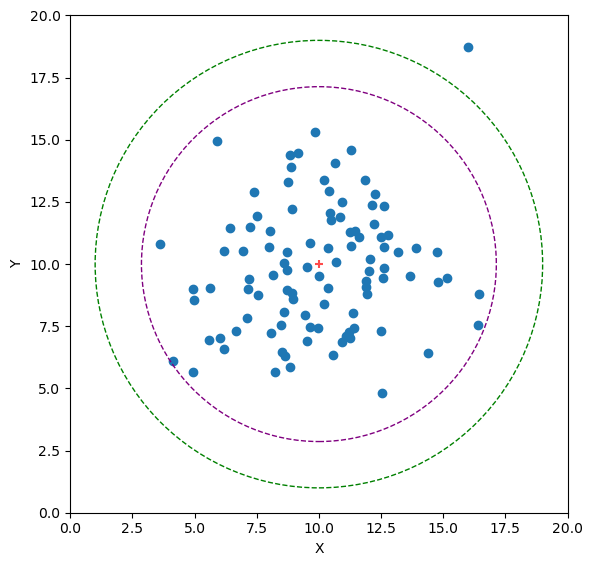

In [52]:
fig, ax = plt.subplots(figsize=(6,6))


ax.scatter(random_points[:, 0], random_points[:, 1])
ax.scatter(mu, mu, color='red', marker='+', alpha=.7)

circle = Circle((mu, mu), 3*sigma, color='green', fill=False, linestyle='--')
ax.add_patch(circle)

circle2 = Circle((mu, mu), radius, color='purple', fill=False, linestyle='--')
ax.add_patch(circle2)

ax.set_xlim([0, 20])
ax.set_ylim([0, 20])

ax.set_xlabel('X')
ax.set_ylabel('Y')

ax.set_aspect('equal')

plt.tight_layout()
plt.show()

# Задание 2

In [86]:
def normal_density(x, mu, sigma):
    return ((1/(sigma*np.sqrt(np.pi)))*np.exp(-((x-mu)**2)/(2*sigma**2)))

In [90]:
x_density = np.arange(0, 20, 0.1)
density = normal_density(np.arange(0, 20, 0.1), mu, sigma)

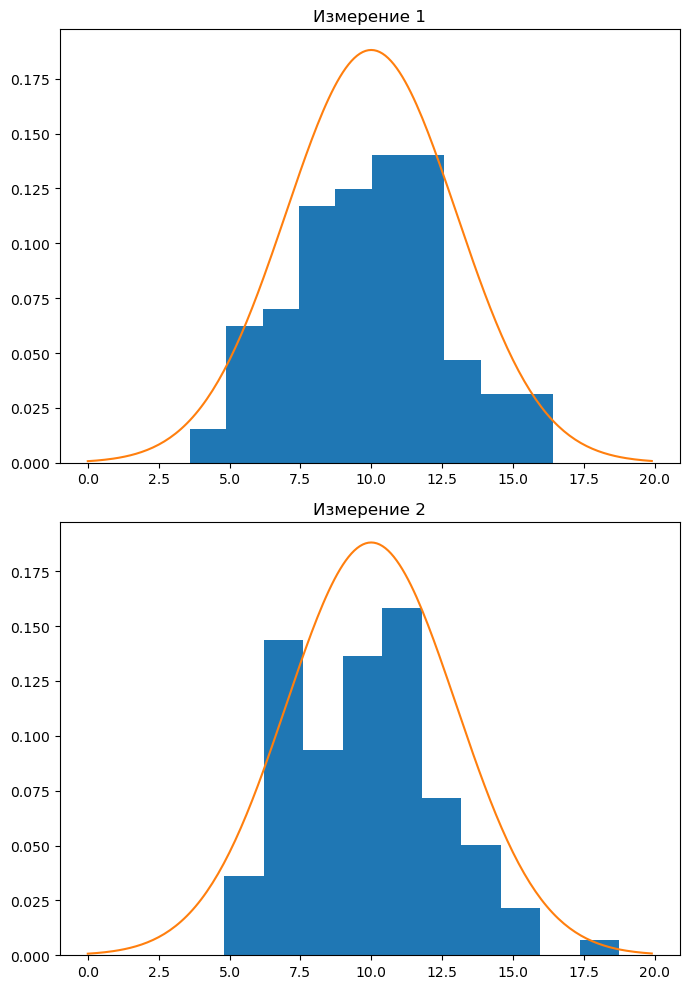

In [93]:
fig, axes = plt.subplots(2,1, figsize=(7,10))

ax1 = axes[0]
ax2 = axes[1]

ax1.hist(random_points[:, 0], bins=10, density=True)
ax2.hist(random_points[:, 1], bins=10, density=True)

ax1.plot(x_density, density)
ax2.plot(x_density, density)

ax1.set_title('Измерение 1')
ax2.set_title('Измерение 2')

plt.tight_layout()
plt.show()

# Задание 3

Источник: https://matplotlib.org/stable/gallery/images_contours_and_fields/image_annotated_heatmap.html

In [96]:
from sklearn.datasets import load_iris

In [97]:
iris = load_iris()

In [107]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [103]:
iris_data = iris.data

In [104]:
iris_data[:5]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2]])

In [105]:
type(iris_data)

numpy.ndarray

In [109]:
corr_matrix = np.corrcoef(iris_data, rowvar=False)

In [116]:
corr_matrix

array([[ 1.        , -0.11756978,  0.87175378,  0.81794113],
       [-0.11756978,  1.        , -0.4284401 , -0.36612593],
       [ 0.87175378, -0.4284401 ,  1.        ,  0.96286543],
       [ 0.81794113, -0.36612593,  0.96286543,  1.        ]])

In [112]:
from matplotlib.colors import LinearSegmentedColormap

In [145]:
my_cmap = LinearSegmentedColormap.from_list('my_custom_cmap',
                                            [(0, 'red'),
                                             (0.5, 'white'),
                                             (1, 'darkgreen')],
                                            N=256)

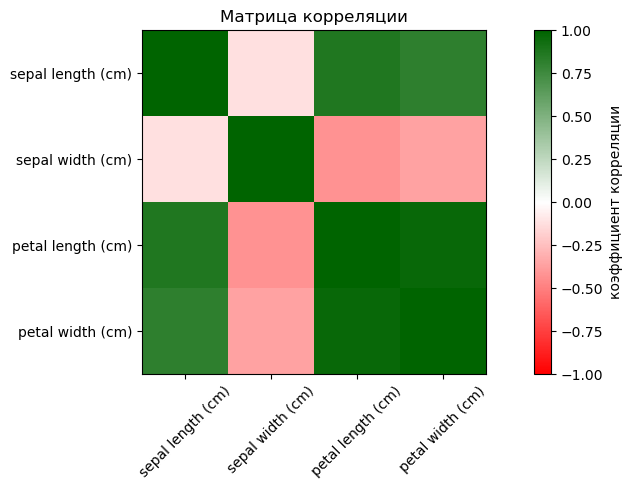

In [146]:
fig,ax = plt.subplots(figsize=(10,5))

image = ax.imshow(corr_matrix, cmap=my_cmap, vmin=-1, vmax=1)

plt.colorbar(image, ax=ax, label='коэффициент корреляции')

ax.set_title('Матрица корреляции')

ax.set_xticks(np.arange(len(iris.feature_names)),
              labels=iris.feature_names,
              rotation=45)

ax.set_yticks(np.arange(len(iris.feature_names)),
              labels=iris.feature_names)

plt.tight_layout()
plt.show()

# Задание 5

In [147]:
import pandas as pd

In [148]:
corr_df = pd.DataFrame(corr_matrix, index=iris.feature_names, columns=iris.feature_names)

In [150]:
corr_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


In [151]:
import seaborn as sns

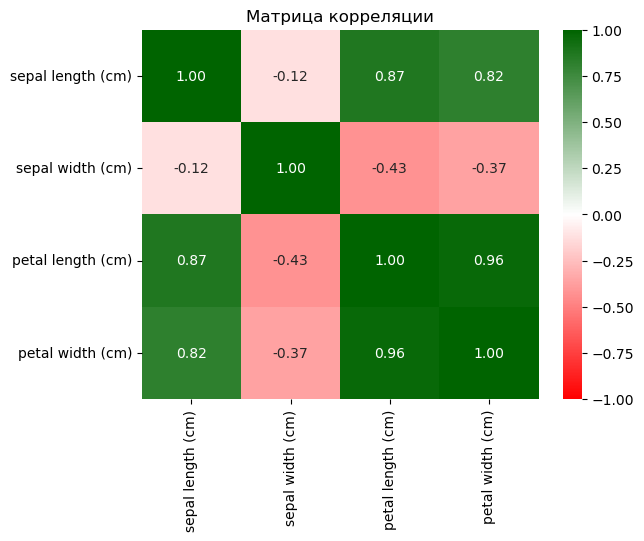

In [159]:
sns.heatmap(corr_df, cmap=my_cmap,vmin=-1, vmax=1, annot=True, fmt='.2f')

plt.title("Матрица корреляции")

plt.show()